# Generate surface for the skull

To generate the surfaces of the skull (inner surface and outer surface) we need a segmentation of the subject containing the skull label. Idealy we select the skull label and then apply a marching cube algorithm to get a surface from the volume. However here we apply some additional steps to make sure that the surfaces are closed and that inner skull is completely inside outer skull. <br>

1. Select all labels inside the skull (blood+brain+csf). This will ensure that the inside of skull is full and make sure that the marching cubes is limited to the outside.
2. Apply closing morphological operators on the segmentation. This is to trully fill everything.
3. Register the MNI template to the subject's image. This will allow us to apply a mask that get's rid of the neck. The neck contains a complicated bone structure that makes correcting the surfaces quite bothersome. It is not usefull for the source reconstruction anyways so we don't mind getting rid of it anyways.
4. Register the MNI mask to the subject and apply it.
5. Apply the marching cube algorithm.
6. Apply a correction to shift inner skull vertices that are outside the outter skull back inside the outer skull. Some blood voxels are flooding outside of the brain (vessels). Because of that, the inner skull and outer skull share some vertices in common. However, vertices of the inner skull need to be inside the outer skull to apply the forward solution. Luckily, these inconveniences only happen below the brain, where the EEG can't measure anyways. So it does not really matter if the correction is rougth.

## Imports

In [1]:
import mindmap as mm
import pyvista as pv
import nibabel as nib
import numpy as np
import scipy as sp
import skimage
import ants

## Data

In [2]:
# files 
sub  = "sub-pat10"
T1   = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/{sub}/ses-preop/anat/{sub}_ses-preop_res-cmp_T1w.nii.gz"
seg  = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/{sub}/ses-preop/anat/m2m_{sub}/final_tissues.nii.gz"
lut  = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/{sub}/ses-preop/anat/m2m_{sub}/final_tissues_LUT.txt"
temp = "/home/admin/work/data/atlas/mni_icbm152_nlin_asym_09c_nifti/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii"
mask = "/home/admin/work/data/atlas/mni_icbm152_nlin_asym_09c_nifti/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c_nino_mask.nii"

seg = mm.utils.Parcellation(seg, lut)

## Registration

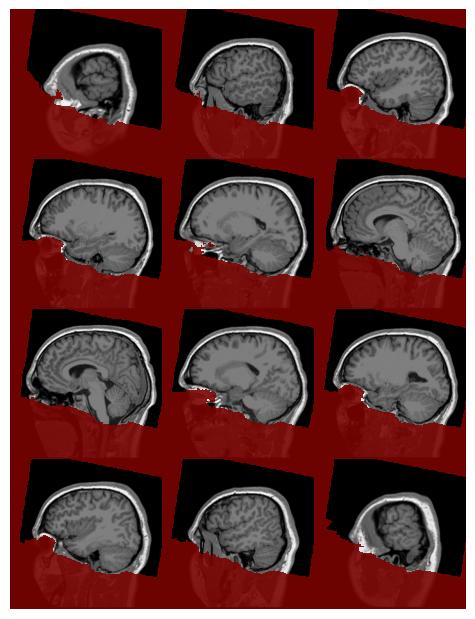

In [3]:
T1_nib = nib.load(T1)
T1   = ants.image_read(T1)
temp = ants.image_read(temp)
mask = ants.image_read(mask)

mytx = ants.registration(T1, temp, "SyN")
mask = ants.apply_transforms(T1, mask, mytx["fwdtransforms"], interpolator="nearestNeighbor")
mask[:,:,:] = np.logical_or(mask[:,:,:], mytx["warpedmovout"][:,:,:]==0)

ants.plot(T1, overlay=mask)

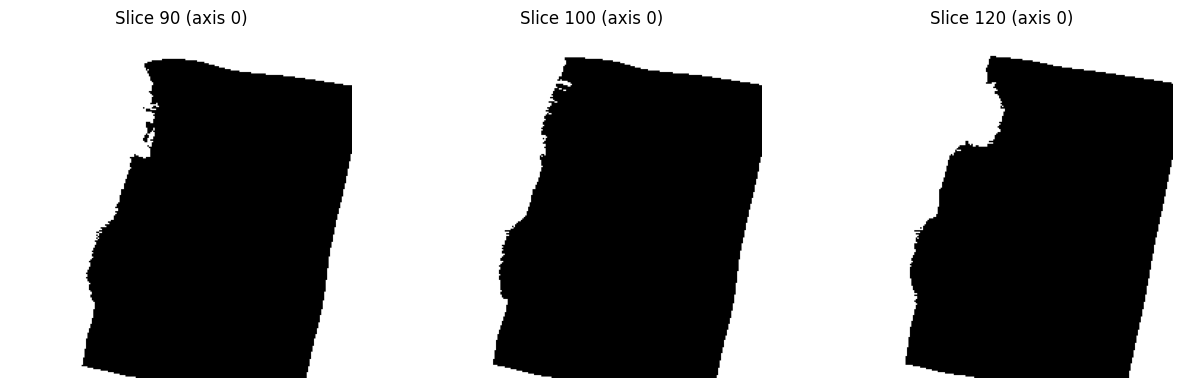

In [4]:
mask = np.logical_or(mask[:,:,:], mytx["warpedmovout"][:,:,:]==0)
mm.viz.show_slices(mask[:,:,:], [90, 100, 120], axis=0)

## Outer Skull

1. Create a mask of the skull
2. Compute the convex hull of this mask

In [5]:
seg.get_clut()

,#No.,Label name,R,G,B,A
0,1,White-Matter,230,230,230,255.0
1,2,Gray-Matter,129,129,129,255.0
2,3,CSF,104,163,255,255.0
3,4,Bone,255,239,179,255.0
4,5,Scalp,255,166,133,255.0
5,6,Eye_balls,255,240,0,255.0
6,7,Compact_bone,255,239,179,255.0
7,8,Spongy_bone,255,138,57,255.0
8,9,Blood,0,65,142,255.0
9,10,Muscle,0,118,14,255.0


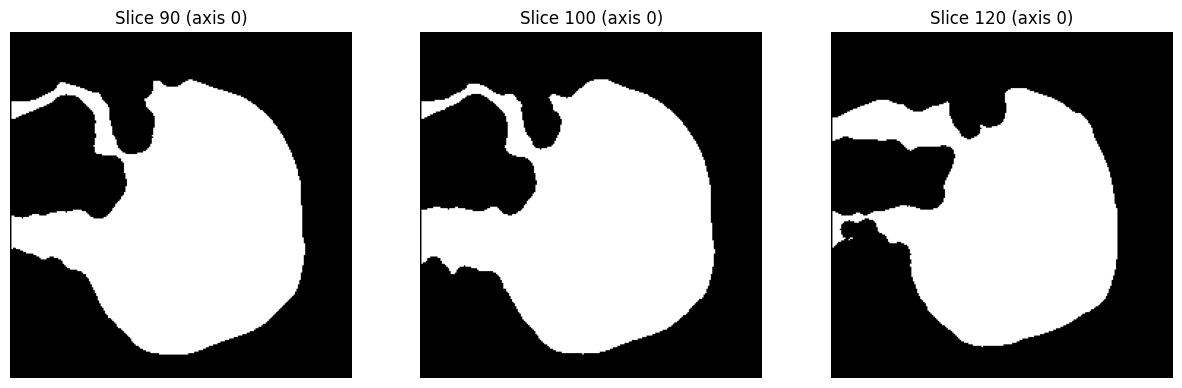

In [6]:
# create skull mask
skull_mask = seg.create_mask([1,2,3,7,8,9]).get_fdata().squeeze()
#skull_mask = skull_mask*(1-mask[:,:,:])
skull_mask = skimage.morphology.isotropic_closing(skull_mask, 10)

# Visualize
slices = [90, 100, 120]
skull_mask[:,:,:1] = 0
mm.viz.show_slices(skull_mask, slices, axis=0)

In [ ]:
vertices, faces, normals, values = skimage.measure.marching_cubes(
    skull_mask,
    step_size=1,
)
oskull = mm.utils.surf_to_polydata(vertices, faces)
oskull = oskull.extract_largest()
#oskull = oskull.decimate(0.7)
#oskull = oskull.clean()
oskull = oskull.smooth(n_iter=1000)
oskull = oskull.compute_normals(auto_orient_normals=True)

plotter = pv.Plotter()
plotter.add_mesh(oskull, color="white", opacity=1, render_points_as_spheres=True)
plotter.show()

/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/backends/aiohttp/__init__.py:95: NotAppKeyWarning:

It is recommended to use web.AppKey instances for keys.
https://docs.aiohttp.org/en/stable/web_advanced.html#application-s-config



Widget(value='<iframe src="http://localhost:43823/index.html?ui=P_0x7ff71d3f2510_0&reconnect=auto" class="pyvi…

Exception raised
ConnectionResetError('Cannot write to closing transport')
Traceback (most recent call last):
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 317, in onCompleteMessage
    await self.sendWrappedMessage(
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 418, in sendWrappedMessage
    await ws.send_bytes(chunk)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/web_ws.py", line 342, in send_bytes
    await self._writer.send(data, binary=True, compress=compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 727, in send
    await self._send_frame(message, WSMsgType.BINARY, compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 682, in _send_frame
    self._write(header + message)
  File "/home/admin/miniconda3/envs/mindmap/lib

## Inner skull
1. Create a mask of everything inside the skull (brain+CSF+blood)
2. Compute the convex hull of this mask

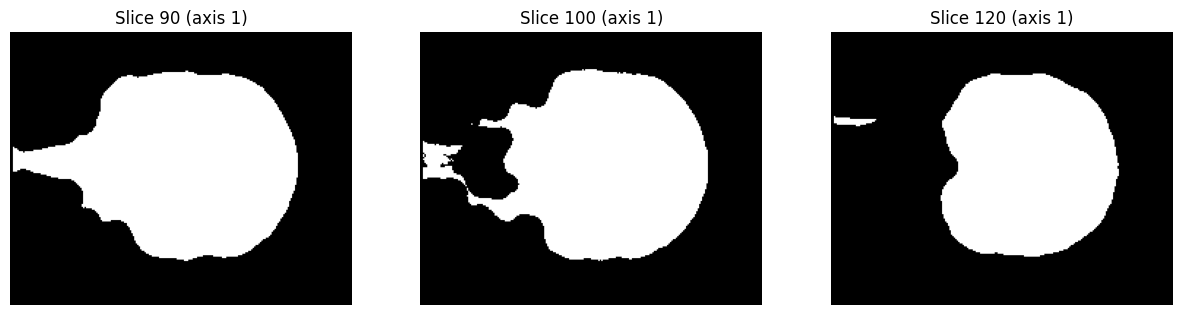

In [38]:
brain_mask = seg.create_mask(regions=[1,2,3,9]).get_fdata().squeeze()
#brain_mask = brain_mask*(1-mask[:,:,:])
brain_mask = skimage.morphology.isotropic_closing(brain_mask, 10)

# visualize
brain_mask[:,:,:2] = 0
mm.viz.show_slices(brain_mask, slices, axis=1)

In [39]:
vertices, faces, normals, values = skimage.measure.marching_cubes(
    brain_mask,
    step_size=1,
)
iskull = mm.utils.surf_to_polydata(vertices, faces)
iskull = iskull.extract_largest()
#iskull = iskull.decimate(0.7)
iskull = iskull.smooth(n_iter=1000)
iskull = iskull.compute_normals(auto_orient_normals=True)

plotter = pv.Plotter()
plotter.add_mesh(iskull, color="pink", opacity=1, render_points_as_spheres=True)
plotter.show()

Widget(value='<iframe src="http://localhost:35449/index.html?ui=P_0x7f21ee94c200_18&reconnect=auto" class="pyv…

In [40]:
plotter = pv.Plotter()
plotter.add_mesh(oskull, color="white", opacity=0.95)
plotter.add_mesh(iskull, color="black")
plotter.show()

Widget(value='<iframe src="http://localhost:35449/index.html?ui=P_0x7f21fb005610_19&reconnect=auto" class="pyv…

## Correct surfaces
The inner skull has a long part at the bottom which goes out ot the outer skull. For EEG source reconstruction, the bottom part is not important but the inner skull should at least be inside the outer skull for mathematical reasons. So we correct the inner skull by pushing the vertices going outside the outer skull back inside.

In [13]:
offset = 0.1

# masks for points on surface, in surface and out surface
onsurf   = (oskull.points[:,None] == iskull.points).all(axis=2).any(axis=0)  # if surfaces are very big, will crash after ~5 min.
insurf   = iskull.select_enclosed_points(oskull, check_surface=True)["SelectedPoints"].astype(bool)
insurf   = insurf * ~onsurf
outsurf  = ~insurf * ~onsurf



In [62]:
# distances of points to surface (ray tracing)
points, rays, _ = oskull.multi_ray_trace(
    iskull.points[~onsurf],
    iskull.point_normals*(insurf.astype(int)-outsurf.astype(int))[:,np.newaxis], 
    first_point=True
)
assert len(rays) == len(iskull.points[~onsurf]), "In surface_correction: Some points don't intersect surface with given direction."

distances = np.zeros(iskull.n_points)
origins   = np.argwhere(~onsurf)
for i in range(rays.max()+1):
    idx1 = np.where(rays==i)[0][0]
    idx2 = origins[i]
    distances[i] = np.linalg.norm(points[idx1]-iskull.points[idx2])

distances  = distances * (outsurf.astype(int)-insurf.astype(int))[:,np.newaxis]
no_corr    = (distances < -offset)
correction = iskull.point_normals * (offset + distances)
correction[no_corr] = 0

new_iskull = iskull.copy(deep=True)
new_iskull.points = iskull.points + correction

AssertionError: In surface_correction: Some points don't intersect surface with given direction.

In [39]:
def easy_surf_correction(iskull, oskull, offset=0.1):
    """Correct iskull. In easy_surf_correction we consider that points to be corrected are only 
    iskull vertices intersecting with the oskull surface.
    
    Parameters
    ----------
    iskull: pv.PolyData
        Inner skull surface.

    oskull: pv.PolyData
        Outer skull surface.

    offset: float 
        Minimum space between inner and outer surface.

    Returns
    -------
    new_iskull: pv.PolyData
        Inner skull with corrected vertices.
    """
    iskull  = iskull.compute_normals(auto_orient_normals=True)
    onsurf  = iskull.select_enclosed_points(oskull, check_surface=True, inside_out=True)["SelectedPoints"]
    onsurf  = onsurf.astype("bool")

    new_iskull = iskull.copy(deep=True)
    correction = -iskull.point_normals[onsurf] * offset
    new_iskull.points[onsurf] = iskull.points[onsurf] + correction

    return new_iskull

oskull = oskull.compute_normals(auto_orient_normals=True)
iskull = easy_surf_correction(iskull, oskull, offset=0.5)

In [40]:
plotter = pv.Plotter()
plotter.add_mesh(oskull, color="white", opacity=1)
plotter.add_mesh(iskull, color="pink")
plotter.show()

Widget(value='<iframe src="http://localhost:43995/index.html?ui=P_0x7fd053e39850_15&reconnect=auto" class="pyv…

In [12]:
# save surfaces freesurfer format
skin_fname   = f"../dataset/spike_sample/derivatives/freesurfer-7.4.1/{sub}/bem/outer_skin.surf"
oskull_fname = f"../dataset/spike_sample/derivatives/freesurfer-7.4.1/{sub}/bem/outer_skull.surf" 
iskull_fname = f"../dataset/spike_sample/derivatives/freesurfer-7.4.1/{sub}/bem/inner_skull.surf" 

# register to FreeSurfer
oskull.points = nib.affines.apply_affine(T1_nib.affine, oskull.points)
iskull.points = nib.affines.apply_affine(T1_nib.affine, iskull.points)

# write surfaces down 
_,_,metadata = nib.freesurfer.read_geometry(skin_fname, read_metadata=True)
mm.io.write_surface(oskull_fname, oskull, metadata)
mm.io.write_surface(iskull_fname, iskull, metadata)

Using surface: /home/admin/work/code/mindmap/evaluations/../dataset/spike_sample/derivatives/freesurfer-7.4.1/sub-pat10/bem/inner_skull.surf
Using surface: /home/admin/work/code/mindmap/evaluations/../dataset/spike_sample/derivatives/freesurfer-7.4.1/sub-pat10/bem/outer_skull.surf
Using surface: /home/admin/work/code/mindmap/evaluations/../dataset/spike_sample/derivatives/freesurfer-7.4.1/sub-pat10/bem/outer_skin.surf


/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/mne/viz/utils.py:167: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



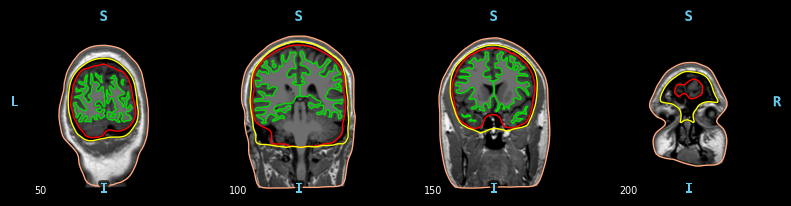

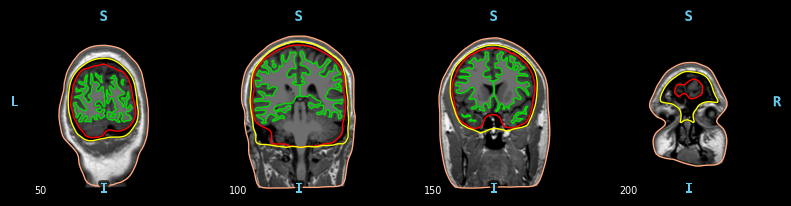

In [44]:
import mne
fs_dir = mm.io.read_config("config.yml")["FS_DIR"]

plot_bem_kwargs = dict(
    subject=sub,
    subjects_dir=fs_dir,
    brain_surfaces="white",
    orientation="coronal",
    slices=[50, 100, 150, 200]
)

mne.viz.plot_bem(**plot_bem_kwargs)

In [28]:
def surf_correction(
        iskull: pv.PolyData,
        oskull: pv.PolyData,
        offset: float = 1,
) -> tuple[pv.PolyData, pv.PolyData]:
    """
    Correct inner/outer skull such that inner skull is inside outer skull everywhere by at least
    an offset distance.

    This code uses ray tracing to determine the distance between every vertex in inner skull and 
    the surface outer skull. Every vertex outside of outer skull or less than a distance 'offset' 
    away from the surface, is displaced along it's normal until it meants the wanted requirements.

    Parameters
    ----------
    iskull: pv.PolyData
        Inner skull.

    oskull: pv.PolyData
        Outer skull.

    offset: float
        Minimmal offset in [mm]. Default is 1 mm.

    Returns
    -------
    new_iskull: pv.PolyData
        Corrected inner skull. 
    
    field_correction: pv.PolyData
        Field correction.
    """
    # Define directions for ray tracing. Directions for iskull points inside of oskull should go along
    # their normal. Directions for iskull points outside of oskull points should go in the opposite 
    # direction as their normal. 
    iskull = iskull.compute_normals(auto_orient_normals=True)
    inside = iskull.select_enclosed_points(oskull)["SelectedPoints"]
    signs  = np.where(inside, 1, -1)
    directions = iskull.point_normals*signs[:,np.newaxis]

    # compute ray tracing 
    points, rays, _ = oskull.multi_ray_trace(iskull.points, directions, first_point=True, retry=True)
    assert len(rays) == len(iskull.points), "In surface_correction: Some points don't intersect surface with given direction."

    # For each point, compute distance to surface
    dist2surf = np.inf*np.ones(iskull.n_points)
    for i in range(rays.max()+1):
        idx = np.where(rays==i)[0][0]
        p = points[idx]
        dist2surf[i] = np.linalg.norm(p-iskull.points[i])

    to_correct = np.ma.mask_or(
        (1-inside).astype(bool),    # vertices outside of oskull
        (dist2surf < offset),       # vertices to close to surface
        shrink=False
    )

    # Correct vertices
    new_iskull = iskull.copy(deep=True)
    correction = to_correct[:,np.newaxis] * iskull.point_normals * (-dist2surf)[:,np.newaxis]
    new_iskull.points = iskull.points + correction
    
    field_correction = pv.PolyData(iskull.points)
    field_correction["vectors"] = np.array(correction)
    field_correction = field_correction.glyph(orient="vectors", scale=True)

    return new_iskull, field_correction